# Exploratory Data Analysis: ULB Credit Card Transactions

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

candidates = [Path.cwd() / 'data/raw/creditcard.csv', Path.cwd().parent / 'data/raw/creditcard.csv']
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Put creditcard.csv in data/raw/ and open the repository folder in VS Code.')
df = pd.read_csv(DATA_PATH)
print('Using:', DATA_PATH.resolve())
print('Shape:', df.shape)
df.head()

Using: C:\Users\Dell\Documents\Codex\2026-10-18\i-x20\outputs\fraud-detection-final-project\data\raw\creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Data quality and class balance

Inspect missing values and exact duplicates before modeling. The training script removes exact duplicate rows before splitting to reduce train/holdout overlap; keep that preprocessing decision documented because repeated events can sometimes be legitimate.

In [2]:
print('Missing cells:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Column types:\n', df.dtypes.value_counts())
counts = df['Class'].value_counts().sort_index().rename(index={0:'Legitimate (0)', 1:'Fraud (1)'})
summary = pd.DataFrame({'transactions': counts, 'percent': counts / len(df) * 100})
summary

Missing cells: 0
Exact duplicate rows: 1081
Column types:
 float64    30
int64       1
Name: count, dtype: int64


,transactions,percent
Class,,
Legitimate (0),284315,99.827251
Fraud (1),492,0.172749


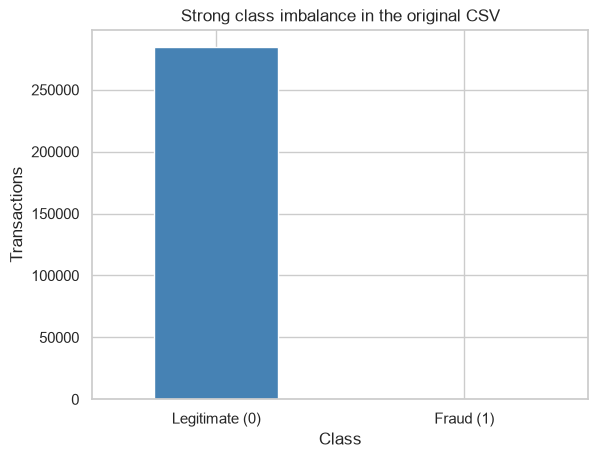

Majority/minority ratio: 577.9:1


In [3]:
ax = summary['transactions'].plot(kind='bar', color=['steelblue','crimson'], title='Strong class imbalance in the original CSV')
ax.set_ylabel('Transactions'); ax.tick_params(axis='x', rotation=0); plt.show()
print(f"Majority/minority ratio: {summary.iloc[0,0] / summary.iloc[1,0]:.1f}:1")

## 2. Amount behavior

Amounts are skewed, so compare medians and quantiles as well as means. A high or low amount alone does not establish fraud.

In [4]:
amount_summary = df.groupby('Class')['Amount'].agg(['count','mean','median','std','min','max'])
amount_summary.index = amount_summary.index.map({0:'Legitimate', 1:'Fraud'})
amount_summary

,count,mean,median,std,min,max
Class,,,,,,
Legitimate,284315,88.291022,22.00,250.105092,0.0,25691.16
Fraud,492,122.211321,9.25,256.683288,0.0,2125.87


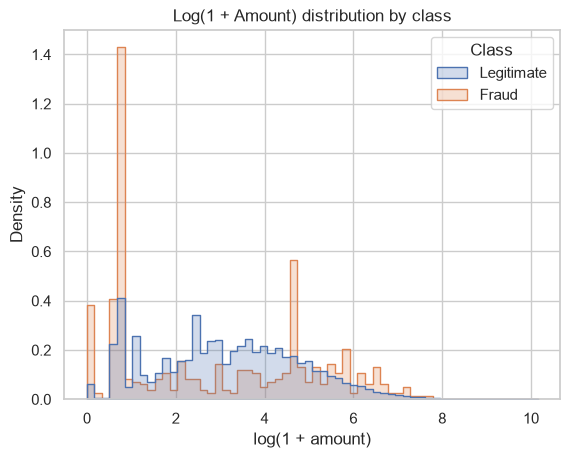

In [5]:
plot_df = df[['Amount','Class']].copy()
plot_df['Class'] = plot_df['Class'].map({0:'Legitimate',1:'Fraud'})
plot_df['log_amount'] = np.log1p(plot_df['Amount'])
sns.histplot(data=plot_df, x='log_amount', hue='Class', bins=60, stat='density', common_norm=False, element='step')
plt.title('Log(1 + Amount) distribution by class'); plt.xlabel('log(1 + amount)'); plt.show()

## 3. Elapsed-time behavior

In [6]:
time_df = df[['Time','Class']].copy()
time_df['time_bin'] = pd.cut(time_df['Time'], bins=20, include_lowest=True)
time_rates = time_df.groupby('time_bin', observed=False).agg(transactions=('Class','size'), fraud=('Class','sum'))
time_rates['fraud_rate_pct'] = 100 * time_rates['fraud'] / time_rates['transactions']
time_rates

,transactions,fraud,fraud_rate_pct
time_bin,,,
"(-172.793, 8639.6]",6830,20,0.292826
"(8639.6, 17279.2]",3680,22,0.597826
"(17279.2, 25918.8]",4185,19,0.454002
"(25918.8, 34558.4]",12770,29,0.227095
"(34558.4, 43198.0]",19932,56,0.280955
"(43198.0, 51837.6]",18594,23,0.123696
"(51837.6, 60477.2]",18833,35,0.185844
"(60477.2, 69116.8]",19717,28,0.142009
"(69116.8, 77756.4]",21140,28,0.132450


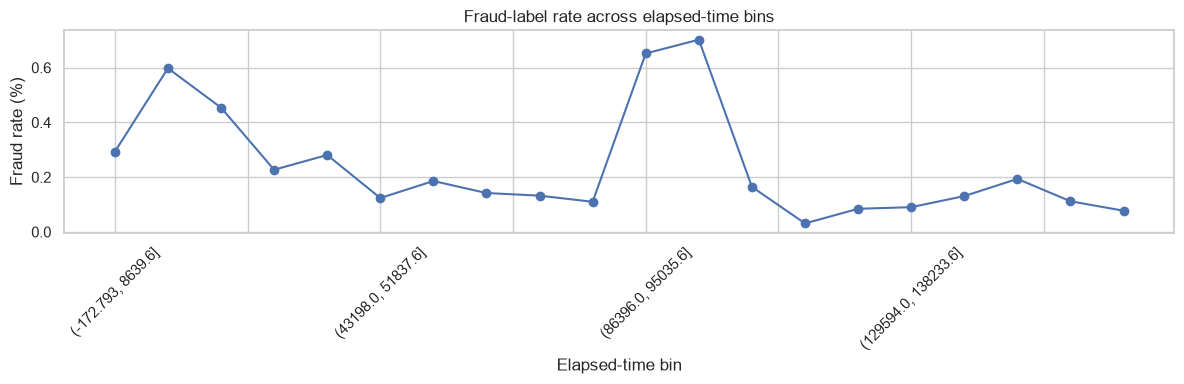

In [7]:
plt.figure(figsize=(12,4))
time_rates['fraud_rate_pct'].plot(marker='o')
plt.title('Fraud-label rate across elapsed-time bins')
plt.xlabel('Elapsed-time bin'); plt.ylabel('Fraud rate (%)'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 4. Anonymized V-features

Rank features by standardized mean difference as a descriptive screen. This ranking is not a causal explanation and cannot reveal the original real-world meaning of the transformed columns.

In [8]:
v_cols = [f'V{i}' for i in range(1,29) if f'V{i}' in df.columns]
groups = df.groupby('Class')[v_cols]
means = groups.mean()
stds = df[v_cols].std()
smd = (means.loc[1] - means.loc[0]) / stds
feature_rank = smd.abs().sort_values(ascending=False).rename('absolute_standardized_mean_difference').to_frame()
feature_rank.head(12)

,absolute_standardized_mean_difference
V17,7.861863
V14,7.285436
V12,6.275236
V10,5.222673
V16,4.732777
V3,4.646614
V7,4.509253
V11,3.729500
V4,3.213497
V18,2.684633


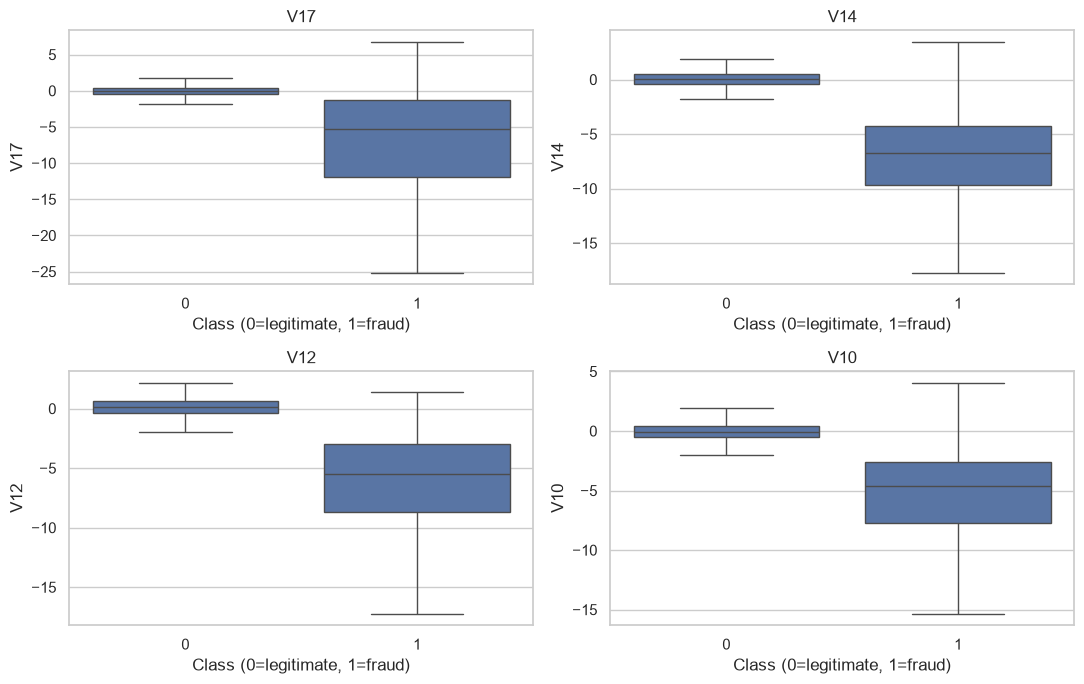

In [9]:
top = feature_rank.head(4).index.tolist()
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax, col in zip(axes.flat, top):
    sns.boxplot(data=df, x='Class', y=col, showfliers=False, ax=ax)
    ax.set_title(col); ax.set_xlabel('Class (0=legitimate, 1=fraud)')
plt.tight_layout(); plt.show()

In [10]:
corr = df[v_cols + ['Class']].corr(numeric_only=True)['Class'].drop('Class').sort_values(key=lambda x: x.abs(), ascending=False)
print('Largest absolute Pearson correlations with Class (descriptive only):')
display(corr.head(10).to_frame('correlation_with_Class'))

Largest absolute Pearson correlations with Class (descriptive only):


,correlation_with_Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447
V18,-0.111485


## EDA takeaways

- The dataset contains **284,807 transactions** and 31 columns: `Time`, `Amount`, 28 anonymized features (`V1`–`V28`), and the target `Class`.
- There are **no missing values**. The data contains **1,081 exact duplicate rows**; the modeling workflow removes these before its train/holdout split.
- The target is highly imbalanced: **284,315 transactions (99.83%) are legitimate** and **492 (0.17%) are fraud**. A model that predicts every transaction as legitimate could therefore appear very accurate while detecting no fraud. Later model comparisons should include recall, precision, F1, and average precision, not accuracy alone.
- Transaction amounts are right-skewed, with a few very large values. The median amount is **$22.00 for legitimate transactions** and **$9.25 for fraud transactions**, while the means are **$88.29** and **$122.21**, respectively. This difference suggests that amount distributions vary, but amount by itself is not enough to identify fraud.
- Fraud-label rates vary across elapsed-time bins. Some bins have higher observed rates, but there are relatively few fraud cases, so these fluctuations should be treated as patterns in this dataset—not proof of a repeating real-world time pattern. `Time` is elapsed seconds, not a clock time or calendar date.
- Several anonymized features, including `V17`, `V14`, `V12`, and `V10`, show large differences between legitimate and fraud distributions in the displayed summaries and boxplots. Because `V1`–`V28` are anonymized principal components, their original business meaning cannot be inferred from these plots.

### What this means for modeling

The rare fraud class makes this an imbalanced classification problem. In the next stage, compare imbalance-handling methods using a chronological split: apply SMOTE only to the training partition and leave the later-time holdout unchanged. Evaluate the models with fraud-focused metrics and review-budget results, because accuracy alone can hide missed fraud.